<div align="center">

# **ML پروژه**
## **نیلوفر محمودی 402102392**
## **استاد شمس الهی**
</div>

<div align="right">

## بخش دوم: خوشه بندی و رگرسیون

<div align="right">

### مرحله 1 : بارگذاری و پیش‌ پردازش داده



In [65]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, Birch
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RandomizedSearchCV, KFold, cross_val_predict
from scipy.optimize import minimize
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
)
from xgboost import XGBRegressor
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 392 #سه رقم آخر شماره دانشجوییمه
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

<div align="right">

#### گام 1 و 2

In [2]:
def find_file(filename):
    candidates = [
        Path.cwd() / filename,
        Path.cwd()/ "upload" / filename,
        Path("/mnt/data") / filename,
        Path.cwd().parent /filename,
    ]
    for path in candidates:
        if path.exists():
            return path
        
student_mat =pd.read_csv(find_file("student-mat.csv"), sep=";")
student_por = pd.read_csv(find_file("student-por.csv"), sep=";")
student_mat['course'] = 'Math'
student_por['course']= 'Portuguese'

datasets = {
    "Math": student_mat,
    "Portuguese": student_por,
}

df= pd.concat([student_mat, student_por], axis=0, ignore_index=True)

print(f'Math: {len(student_mat):,}')
print(f'Portuguese: {len(student_por):,}')
print(f'Course: {df.shape}')
df.head()

Math: 395
Portuguese: 649
Course: (1044, 34)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,course
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6,Math
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6,Math
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10,Math
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15,Math
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10,Math


<div align="right">

#### گام 3



In [3]:
DERIVED_FEATURES = [
    'ratio_fail_study','grade_improvement','grade_average',
    'absences_per_study','risk_G3_lt10','risk_G3_lt12',
]
df['ratio_fail_study'] = df['failures']/ df['studytime']
df['grade_improvement'] = df['G2']- df['G1']
df['grade_average'] = (df['G1']+ df['G2'])/ 2
df['absences_per_study']= df['absences']/ df['studytime']
df['risk_G3_lt10'] = (df['G3']< 10).astype(int)
df['risk_G3_lt12'] =(df['G3'] <12).astype(int)

assert len(DERIVED_FEATURES)== 6
assert all(feature in df.columns for feature in DERIVED_FEATURES)
print('6 Derived Features :')
for i,feature in enumerate(DERIVED_FEATURES,start= 1):
    print(f'{i}. {feature}')
display(df[DERIVED_FEATURES].head(10))

6 Derived Features :
1. ratio_fail_study
2. grade_improvement
3. grade_average
4. absences_per_study
5. risk_G3_lt10
6. risk_G3_lt12


,ratio_fail_study,grade_improvement,grade_average,absences_per_study,risk_G3_lt10,risk_G3_lt12
0,0.000,1,5.500,3.000,1,1
1,0.000,0,5.000,2.000,1,1
2,1.500,1,7.500,5.000,0,1
3,0.000,-1,14.500,0.667,0,0
4,0.000,4,8.000,2.000,0,1
5,0.000,0,15.000,5.000,0,0
6,0.000,0,12.000,0.000,0,1
7,0.000,-1,5.500,3.000,1,1
8,0.000,2,17.000,0.000,0,0
9,0.000,1,14.500,0.000,0,0


<div dir="rtl" align="right">

#### گام 4

ویژگی مشتق شده 5 و 6 رو در خوشه بندی وارد نمی کنیم چون از G3 ساخته شده اند و خود G3 در خوشه بندی حضور دارد و وارد کردن این دو ویژگی باعـث می شود نمره نهایی چندبار به الگوریتم داده شود.

In [4]:
RISK_FLAGS = ['risk_G3_lt10', 'risk_G3_lt12']
X_raw= df.drop(columns=RISK_FLAGS).copy()
categorical_columns =X_raw.select_dtypes(include=['object','category']).columns.tolist()
numerical_columns= X_raw.select_dtypes(exclude=['object','category']).columns.tolist()
preprocessor= ColumnTransformer(
    transformers=[
        ('numerical',StandardScaler(), numerical_columns),
        ('categorical',OneHotEncoder(handle_unknown='ignore', sparse_output=False),categorical_columns),
    ],
    remainder='drop',verbose_feature_names_out=False,
)
X_cluster = preprocessor.fit_transform(X_raw)
encoded_feature_names = preprocessor.get_feature_names_out()
X_encoded = pd.DataFrame(X_cluster, columns=encoded_feature_names, index=df.index)
print(f'Numerical columns count: {len(numerical_columns)}')
print(numerical_columns)
print(f'Categorical columns count: {len(categorical_columns)}')
print(categorical_columns)
print(f'Encoded_shape: {X_encoded.shape}')
display(X_encoded.head(10))

Numerical columns count: 20
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'ratio_fail_study', 'grade_improvement', 'grade_average', 'absences_per_study']
Categorical columns count: 18
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'course']
Encoded_shape: (1044, 65)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,ratio_fail_study,grade_improvement,grade_average,absences_per_study,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,Pstatus_T,Mjob_at_home,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_at_home,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_course,reason_home,reason_other,reason_reputation,guardian_father,guardian_mother,guardian_other,schoolsup_no,schoolsup_yes,famsup_no,famsup_yes,paid_no,paid_yes,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes,course_Math,course_Portuguese
0,1.028,1.242,1.466,0.652,0.036,-0.403,0.069,-0.195,0.733,-0.542,-1.000,-0.381,0.252,-2.084,-1.598,-1.383,-0.364,0.572,-1.897,0.044,1.000,0.000,1.000,0.000,0.000,1.000,1.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,1.000,0.000,1.000,0.000,1.000,0.000,0.000,1.000,0.000,1.000,1.000,0.000,1.000,0.000,1.000,0.000
1,0.221,-1.426,-1.262,-0.715,0.036,-0.403,1.141,-0.195,-0.136,-0.542,-1.000,-0.381,-0.070,-2.084,-1.902,-1.383,-0.364,-0.019,-2.063,-0.188,1.000,0.000,1.000,0.000,0.000,1.000,1.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,1.000,0.000,1.000,0.000,1.000,0.000,0.000,1.000,0.000,1.000,1.000,0.000,1.000,0.000
2,-1.393,-1.426,-1.262,-0.715,0.036,4.171,0.069,-0.195,-1.004,0.555,0.557,-0.381,0.897,-1.413,-0.989,-0.347,2.541,0.572,-1.235,0.509,1.000,0.000,1.000,0.000,0.000,1.000,0.000,1.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,1.000,0.000,0.000,1.000,1.000,0.000,0.000,1.000,0.000,1.000,0.000,1.000,1.000,0.000,1.000,0.000
3,-1.393,1.242,-0.353,-0.715,1.235,-0.403,-1.003,-1.165,-1.004,-0.542,-1.000,1.023,-0.392,1.270,0.839,0.947,-0.364,-0.611,1.083,-0.497,1.000,0.000,1.000,0.000,0.000,1.000,1.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,1.000,0.000
4,-0.586,0.353,0.557,-0.715,0.036,-0.403,0.069,-0.195,-1.004,-0.542,-0.221,1.023,-0.070,-1.748,-0.380,-0.347,-0.364,2.347,-1.069,-0.188,1.000,0.000,1.000,0.000,0.000,1.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,1.000,1.000,0.000,0.000,1.000,0.000,1.000,1.000,0.000,1.000,0.000,1.000,0.000
5,-0.586,1.242,0.557,-0.715,0.036,-0.403,1.141,0.775,-1.004,-0.542,-0.221,1.023,0.897,1.270,1.143,0.947,-0.364,-0.019,1.248,0.509,1.000,0.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,1.000,0.000,1.000,0.000
6,-0.586,-0.537,-0.353,-0.715,0.036,-0.403,0.069,0.775,0.733,-0.542,-1.000,-0.381,-0.714,0.264,0.230,-0.089,-0.364,-0.019,0.255,-0.652,1.000,0.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.000,1.000,0.000,1.000,0.000,1.000,1.000,0.000,1.000,0.000
7,0.221,1.242,1.466,0.652,0.036,-0.403,0.069,-2.135,0.733,-0.542,-1.000,-1.786,0.252,-1.748,-1.902,-1.383,-0.364,-0.611,-1.897,0.044,1.000,0.000,1.000,0.000,0.000,1.000,1.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,1.000,1.000,0.000,1.000,0.000,0.000,1.000,0.000,1.000,1.000,0.000,1.000,0.000,1.000,0.000
8,-1.393,0.353,-0.353,-0.715,0.036,-0.403,0.069,-1.16

<div align="right">

### مرحله 2 : خوشه بندی



<div dir="rtl" align="right">

#### گام 1 

In [5]:
K_Means = KMeans(n_clusters=2,n_init=50,random_state=RANDOM_STATE,)
label_Kmeans= K_Means.fit_predict(X_cluster)
df['cluster_Kmeans']=label_Kmeans
display(df['cluster_Kmeans'].value_counts().sort_index().rename('count').to_frame())

,count
cluster_Kmeans,
0,632
1,412


<div dir="rtl" align="right">

#### گام 2


,count
cluster_Hierarchical,
0,820
1,224


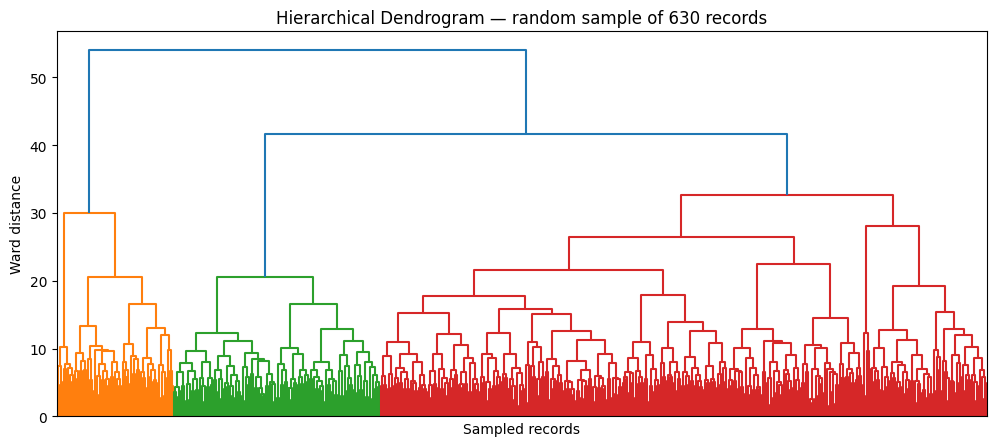

In [6]:
Hierarchical = AgglomerativeClustering(n_clusters=2,linkage='ward',)
label_Hierarchical = Hierarchical.fit_predict(X_cluster)
df['cluster_Hierarchical'] = label_Hierarchical
display(df['cluster_Hierarchical'].value_counts().sort_index().rename('count').to_frame())

sample_size= min(630,len(df))
sample_idx= np.random.default_rng(RANDOM_STATE).choice(len(df), size=sample_size, replace=False)
plt.figure(figsize=(12,5))
dendrogram(linkage(X_cluster[sample_idx],method='ward'), no_labels=True, color_threshold=None)
plt.title(f'Hierarchical Dendrogram — random sample of {sample_size} records')
plt.xlabel('Sampled records')
plt.ylabel('Ward distance')
plt.show()

<div dir="rtl" align="right">

#### گام 3


In [7]:
cluster_columns = [col for col in df.columns if col.startswith('cluster_')]
data_for_analysis = df.drop(columns=cluster_columns).copy()
numeric_columns_analysis = (data_for_analysis.select_dtypes(include=np.number).columns)
categorical_columns_analysis = (data_for_analysis.select_dtypes(exclude=np.number).columns)
categorical_encoded= pd.get_dummies(data_for_analysis[categorical_columns_analysis],drop_first=False,dtype= int)
numeric_original= data_for_analysis[numeric_columns_analysis].copy()
X_analysis = pd.concat([numeric_original,categorical_encoded],axis=1)

kmeans_analysis= X_analysis.copy()
kmeans_analysis['cluster'] =df['cluster_Kmeans']
kmeans_profile= (kmeans_analysis.groupby('cluster').mean())
print("K-Means Cluster Profile")
display(kmeans_profile.round(3))

hierarchical_analysis= X_analysis.copy()
hierarchical_analysis['cluster'] = df['cluster_Hierarchical']
hierarchical_profile = (hierarchical_analysis.groupby('cluster').mean())
print("Hierarchical Clustering Profile")
display(hierarchical_profile.round(3))

def cluster_names(profile):
    ordered = (profile['G3'].sort_values().index.tolist())
    names = {ordered[0]:'Lower Performance / Higher Risk',ordered[1]:'Higher Performance / Lower Risk'}
    return names
kmeans_names = cluster_names(kmeans_profile)
print("K-Means:")
for cluster_id, name in kmeans_names.items():
    print(f"Cluster {cluster_id}: {name}")
hierarchical_names = cluster_names(hierarchical_profile)
print("Hierarchical:")
for cluster_id, name in hierarchical_names.items():
    print(f"Cluster {cluster_id}: {name}")


K-Means Cluster Profile


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,ratio_fail_study,grade_improvement,grade_average,absences_per_study,risk_G3_lt10,risk_G3_lt12,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,Pstatus_T,Mjob_at_home,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_at_home,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_course,reason_home,reason_other,reason_reputation,guardian_father,guardian_mother,guardian_other,schoolsup_no,schoolsup_yes,famsup_no,famsup_yes,paid_no,paid_yes,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes,course_Math,course_Portuguese
cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,16.497,2.880,2.639,1.381,2.161,0.033,3.972,3.089,2.987,1.310,2.022,3.476,3.430,12.930,13.101,13.460,0.018,0.171,13.016,1.977,0.021,0.223,0.832,0.168,0.597,0.403,0.203,0.797,0.698,0.302,0.120,0.880,0.119,0.100,0.373,0.247,0.161,0.054,0.049,0.551,0.261,0.085,0.361,0.264,0.085,0.290,0.255,0.707,0.038,0.889,0.111,0.373,0.627,0.783,0.217,0.472,0.528,0.176,0.824,0.009,0.991,0.158,0.842,0.676,0.324,0.348,0.652
1,17.078,2.180,2.002,1.740,1.677,0.619,3.881,3.374,3.415,1.777,2.687,3.646,5.976,8.580,8.400,8.092,0.448,-0.180,8.490,4.084,0.527,0.954,0.597,0.403,0.519,0.481,0.381,0.619,0.721,0.279,0.109,0.891,0.289,0.046,0.396,0.201,0.068,0.068,0.024,0.573,0.308,0.027,0.490,0.221,0.131,0.158,0.199,0.682,0.119,0.881,0.119,0.408,0.592,0.799,0.201,0.558,0.442,0.238,0.762,0.201,0.799,0.284,0.716,0.597,0.403,0.425,0.575


Hierarchical Clustering Profile


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,ratio_fail_study,grade_improvement,grade_average,absences_per_study,risk_G3_lt10,risk_G3_lt12,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,Pstatus_T,Mjob_at_home,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_at_home,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_course,reason_home,reason_other,reason_reputation,guardian_father,guardian_mother,guardian_other,schoolsup_no,schoolsup_yes,famsup_no,famsup_yes,paid_no,paid_yes,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes,course_Math,course_Portuguese
cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,16.782,2.368,2.232,1.610,1.887,0.323,3.901,3.205,3.211,1.596,2.407,3.556,4.811,10.334,10.280,10.306,0.232,-0.054,10.307,3.135,0.279,0.635,0.700,0.300,0.563,0.437,0.312,0.688,0.702,0.298,0.118,0.882,0.220,0.057,0.422,0.213,0.088,0.063,0.029,0.577,0.288,0.043,0.440,0.251,0.109,0.200,0.241,0.685,0.073,0.862,0.138,0.405,0.595,0.801,0.199,0.529,0.471,0.217,0.783,0.109,0.891,0.243,0.757,0.624,0.376,0.366,0.634
1,16.522,3.464,2.960,1.205,2.277,0.049,4.062,3.188,2.955,1.121,1.835,3.496,3.058,14.433,14.781,15.134,0.025,0.348,14.607,1.616,0.004,0.058,0.884,0.116,0.576,0.424,0.129,0.871,0.723,0.277,0.107,0.893,0.062,0.156,0.237,0.286,0.259,0.045,0.076,0.496,0.250,0.134,0.308,0.232,0.085,0.375,0.201,0.741,0.058,0.973,0.027,0.321,0.679,0.746,0.254,0.420,0.580,0.138,0.862,0.000,1.000,0.080,0.920,0.719,0.281,0.424,0.576


K-Means:
Cluster 1: Lower Performance / Higher Risk
Cluster 0: Higher Performance / Lower Risk
Hierarchical:
Cluster 0: Lower Performance / Higher Risk
Cluster 1: Higher Performance / Lower Risk


<div align="right">

#### گام 4

: دو روش انتخاب‌ شده

**Gaussian Mixture Model (GMM)**

**Fuzzy C-Means**


In [8]:
GMM = GaussianMixture(n_components=2,covariance_type='full',n_init=20,random_state=RANDOM_STATE)
label_GMM= GMM.fit_predict(X_cluster)
df['cluster_GMM'] =label_GMM
display(df['cluster_GMM'].value_counts().sort_index().rename('count').to_frame())

def fuzzy_c_means(X,n_clusters=2,m=2.0,max_iter=500,tol=1e-6,random_state=RANDOM_STATE):
    X =np.asarray(X, dtype=float)
    n_samples= X.shape[0]
    rng =np.random.default_rng(random_state)
    U = rng.random((n_clusters, n_samples))
    U = U/ U.sum(axis=0,keepdims=True)
    for iteration in range(max_iter):
        U_old = U.copy()
        Um =U **m
        centers = ( Um @ X)/ (Um.sum(axis=1, keepdims=True))
        distances =np.linalg.norm( X[None, :, :] - centers[:, None, :],axis=2)
        distances= np.maximum(distances,1e-12)
        exponent= 2.0 /(m - 1.0)
        ratio = (distances[:,None, :] /distances[None,:, :])** exponent
        U= 1.0 / ratio.sum(axis=1)
        if np.max(np.abs(U -U_old))< tol:
            break
    labels= np.argmax(U, axis=0)
    return centers, U, labels, iteration +1


fuzzy_centers,fuzzy_membership,label_Fuzzy, fuzzy_iterations = fuzzy_c_means(
    X_cluster,n_clusters=2,m=2,random_state=RANDOM_STATE
)
df['cluster_Fuzzy'] =label_Fuzzy
fuzzy_partition_coefficient = (np.sum(fuzzy_membership **2) /fuzzy_membership.shape[1])

print(f'\nFuzzy C-Means converged in {fuzzy_iterations} iterations')
display(df['cluster_Fuzzy'].value_counts().sort_index().rename('count').to_frame())
membership_df = pd.DataFrame(fuzzy_membership.T,columns=['membership_cluster_0', 'membership_cluster_1'])
print('\nFirst 10 fuzzy memberships:')
display(membership_df.head(10))

,count
cluster_GMM,
0,779
1,265



Fuzzy C-Means converged in 14 iterations


,count
cluster_Fuzzy,
0,488
1,556



First 10 fuzzy memberships:


,membership_cluster_0,membership_cluster_1
0,0.500,0.500
1,0.500,0.500
2,0.500,0.500
3,0.500,0.500
4,0.500,0.500
5,0.500,0.500
6,0.500,0.500
7,0.500,0.500
8,0.500,0.500
9,0.500,0.500


In [9]:
gmm_analysis = X_analysis.copy()
gmm_analysis["cluster"] = df["cluster_GMM"]
profile_gmm = (gmm_analysis.groupby("cluster").mean())
print("Gaussian Mixture Model Cluster Profile")
display(profile_gmm.round(3))

fuzzy_analysis= X_analysis.copy()
fuzzy_analysis["cluster"] = df["cluster_Fuzzy"]
profile_fuzzy = (fuzzy_analysis.groupby("cluster").mean())
print("\nFuzzy C-Means Cluster Profile")
display(profile_fuzzy.round(3))

names_gmm = cluster_names(profile_gmm)
df["cluster_GMM_name"] =(df["cluster_GMM"].map(names_gmm))
print("\nGMM:")
for cluster_id, cluster_name in names_gmm.items():
    print(f"Cluster {cluster_id}: {cluster_name}")

names_fuzzy =cluster_names(profile_fuzzy)
df["cluster_Fuzzy_name"] = (df["cluster_Fuzzy"].map(names_fuzzy))
print("\nFuzzy C-Means:")
for cluster_id, cluster_name in names_fuzzy.items():
    print(f"Cluster {cluster_id}: {cluster_name}")

Gaussian Mixture Model Cluster Profile


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,ratio_fail_study,grade_improvement,grade_average,absences_per_study,risk_G3_lt10,risk_G3_lt12,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,Pstatus_T,Mjob_at_home,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_at_home,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_course,reason_home,reason_other,reason_reputation,guardian_father,guardian_mother,guardian_other,schoolsup_no,schoolsup_yes,famsup_no,famsup_yes,paid_no,paid_yes,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes,course_Math,course_Portuguese
cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,16.479,2.757,2.516,1.474,2.039,0.000,3.973,3.139,3.103,1.421,2.213,3.504,3.702,11.950,12.041,12.403,0.000,0.091,11.996,2.291,0.121,0.401,0.769,0.231,0.576,0.424,0.250,0.750,0.697,0.303,0.112,0.888,0.160,0.089,0.365,0.232,0.154,0.054,0.045,0.555,0.271,0.076,0.393,0.245,0.101,0.261,0.246,0.754,0.000,0.881,0.119,0.376,0.624,0.779,0.221,0.496,0.504,0.181,0.819,0.000,1.000,0.193,0.807,0.688,0.312,0.366,0.634
1,17.453,2.151,2.011,1.668,1.770,1.042,3.826,3.385,3.313,1.709,2.494,3.657,6.589,9.049,8.909,8.223,0.740,-0.140,8.979,4.330,0.513,0.838,0.653,0.347,0.536,0.464,0.340,0.660,0.736,0.264,0.128,0.872,0.260,0.049,0.434,0.219,0.038,0.075,0.023,0.574,0.306,0.023,0.468,0.253,0.109,0.170,0.192,0.532,0.275,0.902,0.098,0.419,0.581,0.819,0.181,0.536,0.464,0.257,0.743,0.336,0.664,0.253,0.747,0.517,0.483,0.415,0.585



Fuzzy C-Means Cluster Profile


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,ratio_fail_study,grade_improvement,grade_average,absences_per_study,risk_G3_lt10,risk_G3_lt12,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,Pstatus_T,Mjob_at_home,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_at_home,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_course,reason_home,reason_other,reason_reputation,guardian_father,guardian_mother,guardian_other,schoolsup_no,schoolsup_yes,famsup_no,famsup_yes,paid_no,paid_yes,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes,course_Math,course_Portuguese
cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,17.016,2.191,2.010,1.699,1.723,0.531,3.879,3.314,3.357,1.738,2.602,3.689,5.725,8.910,8.744,8.541,0.383,-0.166,8.827,3.864,0.463,0.912,0.629,0.371,0.533,0.467,0.359,0.641,0.717,0.283,0.107,0.893,0.270,0.045,0.408,0.203,0.074,0.072,0.023,0.584,0.295,0.027,0.480,0.234,0.123,0.164,0.205,0.682,0.113,0.869,0.131,0.404,0.596,0.791,0.209,0.545,0.455,0.246,0.754,0.180,0.820,0.277,0.723,0.590,0.410,0.410,0.590
1,16.471,2.966,2.719,1.369,2.187,0.031,3.986,3.103,2.980,1.281,2.005,3.415,3.302,13.236,13.442,13.800,0.017,0.207,13.339,1.883,0.007,0.160,0.836,0.164,0.595,0.405,0.198,0.802,0.698,0.302,0.124,0.876,0.112,0.108,0.360,0.252,0.169,0.049,0.054,0.538,0.266,0.094,0.353,0.259,0.086,0.302,0.257,0.710,0.032,0.901,0.099,0.372,0.628,0.788,0.212,0.471,0.529,0.160,0.840,0.002,0.998,0.147,0.853,0.692,0.308,0.351,0.649



GMM:
Cluster 1: Lower Performance / Higher Risk
Cluster 0: Higher Performance / Lower Risk

Fuzzy C-Means:
Cluster 0: Lower Performance / Higher Risk
Cluster 1: Higher Performance / Lower Risk


In [10]:
def evaluate_clustering(labels, method_name):
    unique_labels =np.unique(labels)
    if len(unique_labels) < 2:
        return {'Method':method_name,'Silhouette':np.nan,'Davies_Bouldin': np.nan,}
    return {
        'Method': method_name,
        'Silhouette':silhouette_score(X_cluster, labels),
        'Davies_Bouldin':davies_bouldin_score(X_cluster, labels),
    }

cluster_results = pd.DataFrame([
    evaluate_clustering(label_Kmeans,'K-Means'),evaluate_clustering(label_Hierarchical, 'Hierarchical'),
    evaluate_clustering(label_GMM, 'GMM'),evaluate_clustering(label_Fuzzy, 'Fuzzy C-Means')
])
cluster_results['Rank_Silhouette'] = (cluster_results['Silhouette'].rank(ascending=False, method='min'))
cluster_results['Rank_Davies_Bouldin'] =(cluster_results['Davies_Bouldin'].rank(ascending=True, method='min'))
cluster_results['Total_Rank'] = (cluster_results[['Rank_Silhouette','Rank_Davies_Bouldin',]].sum(axis=1))
cluster_results = (
    cluster_results.sort_values(['Total_Rank','Silhouette'],ascending=[True, False]).reset_index(drop=True)
)
display(cluster_results.round(3))
best_clustering_method =cluster_results.iloc[0]['Method']
print(f'Best method is: {best_clustering_method}')

,Method,Silhouette,Davies_Bouldin,Rank_Silhouette,Rank_Davies_Bouldin,Total_Rank
0,K-Means,0.122,2.728,2.000,1.000,3.000
1,GMM,0.128,3.086,1.000,4.000,5.000
2,Fuzzy C-Means,0.107,2.755,3.000,2.000,5.000
3,Hierarchical,0.041,2.809,4.000,3.000,7.000


Best method is: K-Means


<div align="right">

### مرحله 3 : رگرسیون 



<div dir="rtl" align="right">

#### گام 1 
ستون G3 هم حذف می کنیم چون G3 هدف رگرسیون است.

In [11]:
X_regression = X_encoded.drop(columns=['G3']).copy()
y_regression = df['G3'].copy()
X_train,X_test, y_train,y_test = train_test_split(X_regression,y_regression,test_size=0.2,random_state=RANDOM_STATE)
print(f'Train shape: {X_train.shape}')
print(f'Test shape: {X_test.shape}')

Train shape: (835, 64)
Test shape: (209, 64)


<div dir="rtl" align="right">

#### گام 2
دو مدل دیگر:

**Linear Regression**

**Gradient Boosting Regressor**


In [12]:
regression_models = {
    'Random Forest': RandomForestRegressor(
        n_estimators=500,random_state=RANDOM_STATE,n_jobs=-1
    ),

    'XGBoost': XGBRegressor(
        n_estimators=500,learning_rate=0.03,max_depth=4,
        subsample=0.85,colsample_bytree=0.85,
        objective='reg:squarederror',
        random_state=RANDOM_STATE,n_jobs=-1
    ),

    'Linear Regression': LinearRegression(),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=300,learning_rate=0.03,
        max_depth=3,random_state=RANDOM_STATE
    )
}
trained_models ={}
regression_predictions= {}
for model_name,model in regression_models.items():
    model.fit(X_train, y_train)
    trained_models[model_name]= model
    regression_predictions[model_name] =model.predict(X_test)

<div dir="rtl" align="right">

#### گام 3

In [13]:
regression_results = []
for model_name,predictions in regression_predictions.items():
    MAE =mean_absolute_error(y_test,predictions)
    RMSE= np.sqrt(mean_squared_error(y_test,predictions))
    R2 = r2_score(y_test,predictions)
    regression_results.append({
        'Model': model_name,
        'MAE': MAE,'RMSE': RMSE,'R2': R2
    })
regression_results = (pd.DataFrame(regression_results)
    .sort_values(['RMSE','MAE'],ascending=True).reset_index(drop=True)
)
display(regression_results.round(4))

,Model,MAE,RMSE,R2
0,Random Forest,0.997,1.654,0.843
1,Gradient Boosting,1.035,1.714,0.832
2,XGBoost,1.029,1.724,0.830
3,Linear Regression,1.097,1.802,0.814


<div dir="rtl" align="right">

#### گام 4


In [14]:
best_regression_model= regression_results.iloc[0]['Model']
print(f'Best regression model: {best_regression_model}')
best_row =regression_results.iloc[0]
print(f"MAE = {best_row['MAE']:.3f} | "f"RMSE = {best_row['RMSE']:.3f} | "f"R2 = {best_row['R2']:.3f}")
if best_regression_model in ['Random Forest','XGBoost','Gradient Boosting']:
    print('This result shows that nonlinear relations are important for predicting G3.')

Best regression model: Random Forest
MAE = 0.997 | RMSE = 1.654 | R2 = 0.843
This result shows that nonlinear relations are important for predicting G3.


<div dir="rtl" align="right">

## پرسش 1

مقادیر مختلف k از 2 تا 10 بررسی می‌ شوند و نتیجه با مقدار اولیه k=2 مقایسه خواهد شد.

</div>

In [15]:
k_values = range(2,11)
silhouette_scores=[]
davies_scores =[]

for k in k_values:
    model= KMeans(n_clusters=k,n_init=50,random_state=RANDOM_STATE)
    labels= model.fit_predict(X_cluster)
    silhouette_scores.append(silhouette_score(X_cluster, labels))
    davies_scores.append(davies_bouldin_score(X_cluster, labels))
    
k_result = pd.DataFrame({'k': list(k_values),'Silhouette': silhouette_scores,'Davies_Bouldin': davies_scores})
display(k_result.round(3))

,k,Silhouette,Davies_Bouldin
0,2,0.122,2.728
1,3,0.080,2.905
2,4,0.070,2.804
3,5,0.073,2.613
4,6,0.073,2.567
5,7,0.068,2.583
6,8,0.058,2.666
7,9,0.060,2.609
8,10,0.053,2.706


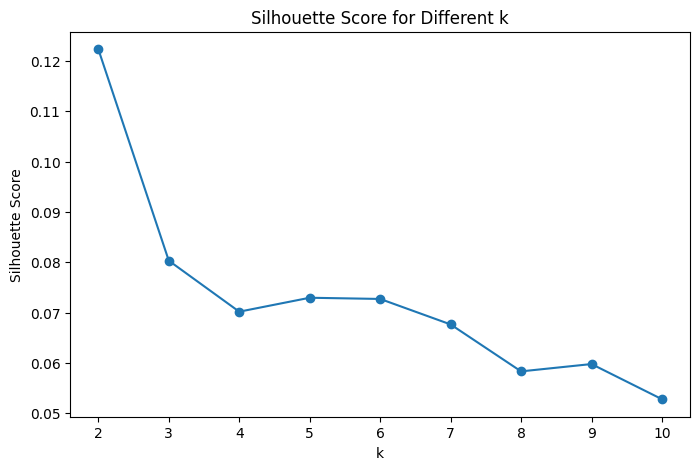

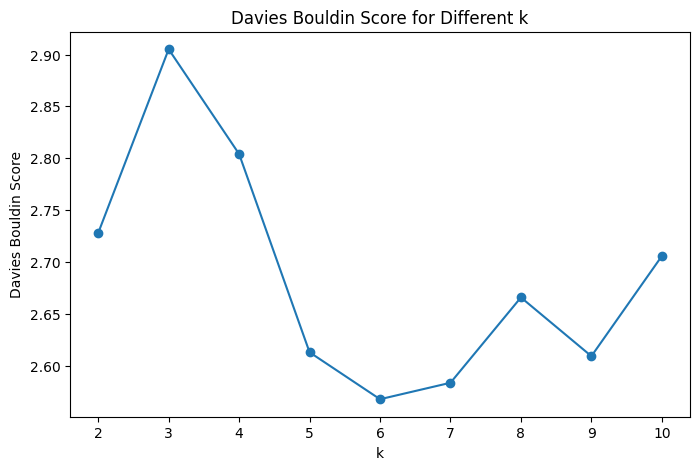

Best k based on Silhouette Score: 2
Best k based on Davies-Bouldin Index: 6


In [16]:
plt.figure(figsize=(8,5))
plt.plot(k_result['k'],k_result['Silhouette'],marker='o')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different k')
plt.xticks(k_result['k'])
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(k_result['k'],k_result['Davies_Bouldin'],marker='o')
plt.xlabel('k')
plt.ylabel('Davies Bouldin Score')
plt.title('Davies Bouldin Score for Different k')
plt.xticks(k_result['k'])
plt.show()

best_k_silhouette = k_result.loc[k_result['Silhouette'].idxmax(),'k']
best_k_davies = k_result.loc[k_result['Davies_Bouldin'].idxmin(),'k']
print('Best k based on Silhouette Score:',best_k_silhouette)
print('Best k based on Davies-Bouldin Index:',best_k_davies)

In [17]:
k_result['Silhouette_Rank'] = (k_result['Silhouette'].rank(ascending=False))
k_result['Davies_Rank']= (k_result['Davies_Bouldin'].rank(ascending=True))
k_result['Total_Rank'] =(k_result['Silhouette_Rank']+k_result['Davies_Rank'])
display(k_result.sort_values('Total_Rank').round(3))
best_k= (k_result.sort_values('Total_Rank').iloc[0]['k'])
print('Final selected k :',int(best_k))

,k,Silhouette,Davies_Bouldin,Silhouette_Rank,Davies_Rank,Total_Rank
4,6,0.073,2.567,4.000,1.000,5.000
3,5,0.073,2.613,3.000,4.000,7.000
5,7,0.068,2.583,6.000,2.000,8.000
0,2,0.122,2.728,1.000,7.000,8.000
7,9,0.060,2.609,7.000,3.000,10.000
1,3,0.080,2.905,2.000,9.000,11.000
2,4,0.070,2.804,5.000,8.000,13.000
6,8,0.058,2.666,8.000,5.000,13.000
8,10,0.053,2.706,9.000,6.000,15.000


Final selected k : 6


<div dir="rtl" align="right">

## پرسش 2



,Method,Silhouette,Davies_Bouldin
0,K-Means,0.122,2.728
1,Hierarchical,0.041,2.809


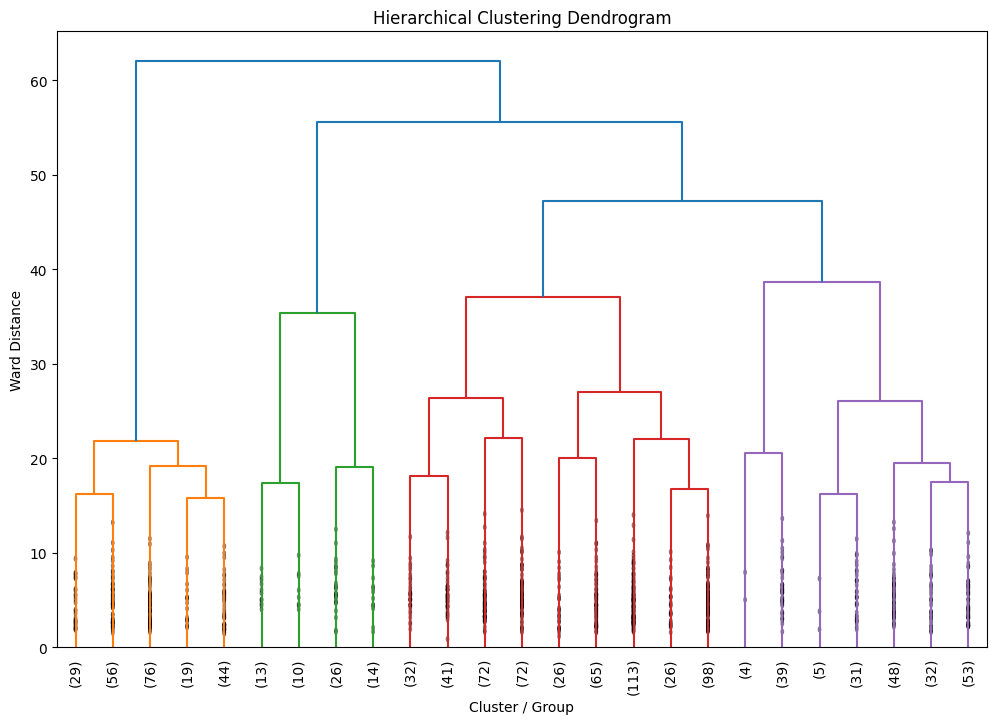

In [18]:
question2_results = pd.DataFrame([
    {'Method': 'K-Means',
     'Silhouette':silhouette_score(X_cluster,label_Kmeans),
     'Davies_Bouldin': davies_bouldin_score(X_cluster,label_Kmeans)},
    {'Method': 'Hierarchical',
     'Silhouette': silhouette_score(X_cluster,label_Hierarchical),
     'Davies_Bouldin': davies_bouldin_score(X_cluster,label_Hierarchical)}
])
display(question2_results.round(3))

Z =linkage(X_cluster,method='ward')
plt.figure(figsize=(12,8))
dendrogram(Z,truncate_mode='lastp',p=25,leaf_rotation=90,leaf_font_size=10,show_contracted=True)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Cluster / Group')
plt.ylabel('Ward Distance')
plt.show()

<div dir="rtl" align="right">

## پرسش 3

بهترین مدل رگرسیون طبق نتایج گام 4 مرحله 3 Random Forest است.
</div>

,Model,Train_RMSE,Test_RMSE,RMSE_Gap,Train_R2,Test_R2,R2_Gap
0,Random Forest,0.520,1.654,1.134,0.981,0.843,0.138
3,Gradient Boosting,0.964,1.714,0.750,0.935,0.832,0.103
1,XGBoost,0.533,1.724,1.190,0.980,0.830,0.150
2,Linear Regression,1.448,1.802,0.354,0.853,0.814,0.039


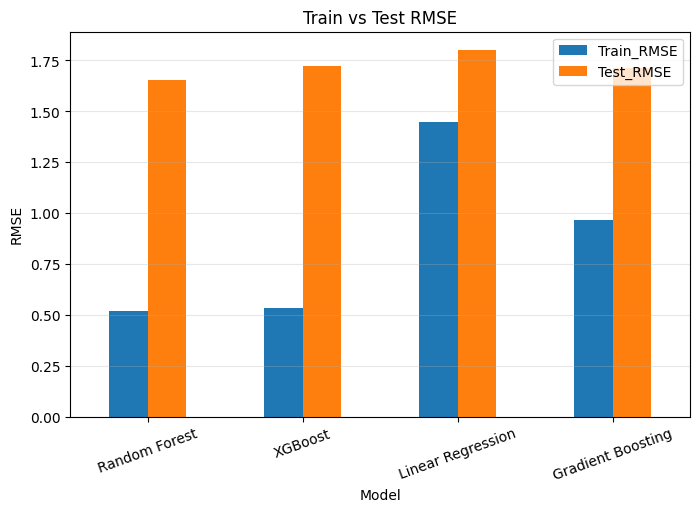

In [19]:
bias_variance_results = []

for model_name,model in trained_models.items():
    train_prediction =model.predict(X_train)
    test_prediction= model.predict(X_test)
    train_RMSE= np.sqrt(mean_squared_error(y_train,train_prediction))
    test_RMSE = np.sqrt(mean_squared_error(y_test,test_prediction))
    train_R2 =r2_score(y_train,train_prediction)
    test_R2 = r2_score(y_test,test_prediction)
    bias_variance_results.append({
        'Model': model_name,
        'Train_RMSE': train_RMSE,'Test_RMSE': test_RMSE,'RMSE_Gap': test_RMSE - train_RMSE,
        'Train_R2': train_R2,'Test_R2': test_R2,'R2_Gap': train_R2 - test_R2
    })

bias_variance_results = pd.DataFrame(bias_variance_results)
display(bias_variance_results.sort_values('Test_RMSE').round(4))

plot_data =(bias_variance_results.set_index('Model')[['Train_RMSE','Test_RMSE']])
plot_data.plot(kind='bar',figsize=(8, 5))
plt.ylabel('RMSE')
plt.title('Train vs Test RMSE')
plt.xticks(rotation=20)
plt.grid(axis='y',alpha=0.3)
plt.show()

<div dir="rtl" align="right">

بهترین مدل از نظر پیش بینی روی داده های جدید Random Forest است این مدل بایاس خوبی دارد ولی واریانس آن زیاد است. در عوض linear Regression واریانس کمی دارد و تست و آموزش به هم نزدیک هستند ولی بایاس زیادی دارد.

بهترین مدل اما از ظر Bias-Variance مدل Gradiant Boosting است چون تعادل بهتری بین دقت و قدرت تعمیم دارد.
</div>

<div dir="rtl" align="right">

## پرسش 4

برای جلوگیری از نشت اطلاعات علاوه بر G2، ویژگی‌ های مشتق‌ شده ای که برای محاسبه آن ها به G2 نیاز داریم یعنی grade_improvement و grade_average نیز حذف می‌ شوند. 
</div>

In [20]:
features_after_G1 = ['G2','grade_improvement','grade_average']
X_early= X_regression.drop(columns=[col for col in features_after_G1 if col in X_regression.columns])
X_train_early= X_early.loc[X_train.index]
X_test_early = X_early.loc[X_test.index]
print("Early train shape:", X_train_early.shape)
print("Early test shape:", X_test_early.shape)

early_model = clone(regression_models[best_regression_model])
early_model.fit(X_train_early,y_train)
early_prediction= early_model.predict(X_test_early)

early_MAE =mean_absolute_error(y_test,early_prediction)
early_RMSE = np.sqrt(mean_squared_error(y_test,early_prediction))
early_R2= r2_score(y_test,early_prediction)

full_result= regression_results[regression_results['Model']== best_regression_model].iloc[0]
q4_results = pd.DataFrame([
    {'Scenario': 'All Features',
     'MAE': full_result['MAE'],'RMSE': full_result['RMSE'],'R2': full_result['R2']},
    {'Scenario': 'Before G2',
     'MAE': early_MAE,'RMSE': early_RMSE,'R2': early_R2}
])
display(q4_results.round(3))

Early train shape: (835, 61)
Early test shape: (209, 61)


,Scenario,MAE,RMSE,R2
0,All Features,0.997,1.654,0.843
1,Before G2,1.495,2.260,0.707


Best model: Random Forest
MAE increase: 0.4985
RMSE increase: 0.6058
R2 decrease: 0.1360


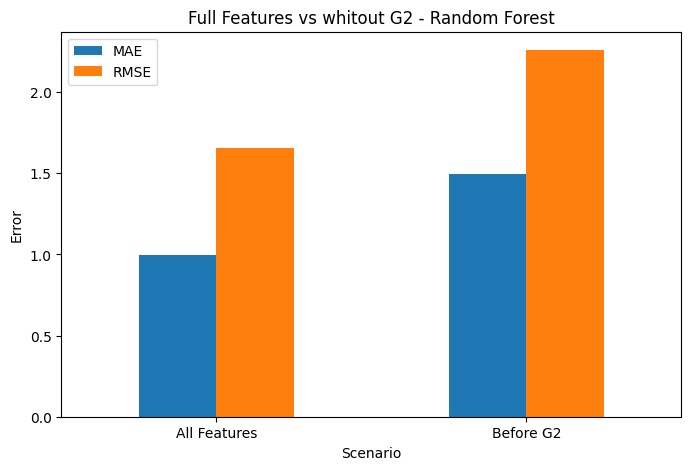

In [21]:
MAE_increase= (early_MAE - full_result['MAE'])
RMSE_increase = (early_RMSE - full_result['RMSE'])
R2_decrease= (full_result['R2'] - early_R2)

print(f"Best model: {best_regression_model}")
print(f"MAE increase: {MAE_increase:.4f}")
print(f"RMSE increase: {RMSE_increase:.4f}")
print(f"R2 decrease: {R2_decrease:.4f}")

q4_results.set_index('Scenario')[['MAE','RMSE']].plot(kind='bar',figsize=(8,5))
plt.ylabel('Error')
plt.title(f'Full Features vs whitout G2 - {best_regression_model}')
plt.xticks(rotation=0)
plt.show()

<div dir="rtl" align="right">


## پرسش 5

</div>

In [22]:
derived_features_in_regression = [feature for feature in DERIVED_FEATURES if feature in X_regression.columns]
X_without_derived = X_regression.drop(columns=derived_features_in_regression)

print("Features With derived features:",X_regression.shape[1])
print("Features WITHOUT derived features:",X_without_derived.shape[1])
XTrain_without_derived =(X_without_derived.loc[X_train.index])
XTest_without_derived= (X_without_derived.loc[X_test.index])
XGBoost_without_derived= clone(regression_models['XGBoost'])
XGBoost_without_derived.fit(XTrain_without_derived,y_train)
prediction_without_derived = (XGBoost_without_derived.predict(XTest_without_derived))
MAE_without = mean_absolute_error(y_test,prediction_without_derived)
RMSE_without= np.sqrt(mean_squared_error(y_test,prediction_without_derived))
R2_without= r2_score(y_test,prediction_without_derived)

XGBoost_result= regression_results[regression_results['Model'] == 'XGBoost'].iloc[0]
q5_results = pd.DataFrame([
    {
        'XGBoost': 'With Derived Features',
        'MAE': XGBoost_result['MAE'],'RMSE': XGBoost_result['RMSE'],'R2': XGBoost_result['R2']
    },
    {
        'XGBoost':'Without Derived Features',
        'MAE': MAE_without,'RMSE': RMSE_without,'R2': R2_without
    }
])
display(q5_results.round(4))

Features With derived features: 64
Features WITHOUT derived features: 60


,XGBoost,MAE,RMSE,R2
0,With Derived Features,1.029,1.724,0.830
1,Without Derived Features,1.048,1.738,0.827


In [23]:
RMSE_increase2 = (RMSE_without -XGBoost_result['RMSE'])
MAE_increase2 = (MAE_without -XGBoost_result['MAE'])
R2_decrease2= (XGBoost_result['R2'] -R2_without)

print(f"MAE increase : {MAE_increase2:.4f}")
print(f"RMSE increase : {RMSE_increase2:.4f}")
print(f"R2 decrease: {R2_decrease2:.4f}")

MAE increase : 0.0190
RMSE increase : 0.0148
R2 decrease: 0.0029


<div dir="rtl" align="right">

## پرسش 6

ترکیب داده های ریاضی و پرتغالی می‌ تواند باعث ایجاد بایاس شود، زیرا تعداد نمونه های دو درس یکسان نیست و همچنین توزیع دانش‌ آموزان بین مدارس مختلف می‌ تواند متفاوت باشد.

برای تشخیص بایاس از اختلاف MAE و RMSE میان گروه ها استفاده می‌ کنیم. اگر مدل در یک درس یا مدرسه خطای بسیار بیشتری داشته باشد می توان نتیجه گرفت که عملکرد مدل برای گروه های مختلف یکسان نیست.

</div>

In [24]:
display(pd.crosstab(df['school'],df['course']))

best_model= trained_models[best_regression_model]
pred = best_model.predict(X_test)
q6_df= df.loc[X_test.index, ['course','school']].copy()
q6_df['G3_true'] = y_test.values
q6_df['G3_pred'] =pred

def evaluate_group(data, column):
    results = []
    for group,part in data.groupby(column):
        MAE= mean_absolute_error(part['G3_true'],part['G3_pred'])
        RMSE =np.sqrt(mean_squared_error(part['G3_true'],part['G3_pred']))
        results.append({
            column: group,
            'Count': len(part),
            'MAE': MAE,
            'RMSE':RMSE
        })
    return pd.DataFrame(results)
course_results =evaluate_group(q6_df,'course')
display(course_results.round(3))
school_results = evaluate_group(q6_df,'school')
display(school_results.round(3))

course_MAE_gap = (course_results['MAE'].max()-course_results['MAE'].min( ))
course_RMSE_gap =(course_results['RMSE'].max()-course_results['RMSE'].min())
school_MAE_gap = (school_results['MAE'].max()- school_results['MAE'].min())
school_RMSE_gap= ( school_results['RMSE'].max()-school_results['RMSE'].min())
print(f"Course MAE gap: {course_MAE_gap:.4f}")
print(f"Course RMSE gap: {course_RMSE_gap:.4f}")
print(f"School MAE gap: {school_MAE_gap:.4f}")
print(f"School RMSE gap: {school_RMSE_gap:.4f}")

course,Math,Portuguese
school,,
GP,349,423
MS,46,226


,course,Count,MAE,RMSE
0,Math,70,0.958,1.458
1,Portuguese,139,1.016,1.745


,school,Count,MAE,RMSE
0,GP,148,0.927,1.445
1,MS,61,1.167,2.077


Course MAE gap: 0.0581
Course RMSE gap: 0.2865
School MAE gap: 0.2406
School RMSE gap: 0.6320


In [25]:
train_groups = df.loc[X_train.index,['course','school']].copy()
train_groups['group']= (train_groups['course'].astype(str)+ '_'+train_groups['school'].astype(str))
group_counts =train_groups['group'].value_counts()
sample_weights = train_groups['group'].map(lambda group:len(train_groups)/(len(group_counts)*group_counts[group]))
weight_table= pd.DataFrame({'Group': train_groups['group'],'Weight': sample_weights})

print("Sample weights:")
display(weight_table.groupby('Group').agg(
        Count=('Weight', 'size'),Weight=('Weight','first')
    ).round(3)
)

weighted_model= clone(regression_models[best_regression_model])
weighted_model.fit(X_train,y_train,sample_weight=sample_weights.values)
weighted_pred= weighted_model.predict(X_test)
q6_weighted =df.loc[X_test.index,['course','school']].copy()
q6_weighted['G3_true'] = y_test.values
q6_weighted['G3_pred']= weighted_pred
course_results_weighted = evaluate_group(q6_weighted,'course')
school_results_weighted =evaluate_group(q6_weighted,'school')

print("Course results after weighting:")
display(course_results_weighted.round(3))
print("School results after weighting:")
display(school_results_weighted.round(3))

course_MAE_GapWeighted =(course_results_weighted['MAE'].max()-course_results_weighted['MAE'].min())
course_RMSA_GapWeighted = (course_results_weighted['RMSE'].max()-course_results_weighted['RMSE'].min())
school_MAE_GapWeighted =(school_results_weighted['MAE'].max() -school_results_weighted['MAE'].min())
school_RMSE_GapWeighted = (school_results_weighted['RMSE'].max()-school_results_weighted['RMSE'].min())

Sample weights:


,Count,Weight
Group,,
Math_GP,289,0.722
Math_MS,36,5.799
Portuguese_GP,335,0.623
Portuguese_MS,175,1.193


Course results after weighting:


,course,Count,MAE,RMSE
0,Math,70,0.963,1.530
1,Portuguese,139,1.015,1.732


School results after weighting:


,school,Count,MAE,RMSE
0,GP,148,0.942,1.493
1,MS,61,1.132,2.029


In [26]:
bias_comparison= pd.DataFrame({
    'Group': ['Course','School'],
    'MAE Gap Before': [course_MAE_gap,school_MAE_gap],
    'MAE Gap After':[course_MAE_GapWeighted,school_MAE_GapWeighted],
    'RMSE Gap Before': [course_RMSE_gap,school_RMSE_gap],
    'RMSE Gap After': [course_RMSA_GapWeighted,school_RMSE_GapWeighted]
})
display(bias_comparison.round(4))

,Group,MAE Gap Before,MAE Gap After,RMSE Gap Before,RMSE Gap After
0,Course,0.058,0.051,0.286,0.202
1,School,0.241,0.190,0.632,0.536


<div align="right">

## پرسش 7


Feature importance from Random Forest:


,Feature,Model_Importance
0,G2,0.734
1,grade_average,0.096
2,absences,0.033
3,absences_per_study,0.032
4,age,0.008
5,studytime,0.005
6,health,0.005
7,reason_home,0.005
8,course_Portuguese,0.005
9,famrel,0.005


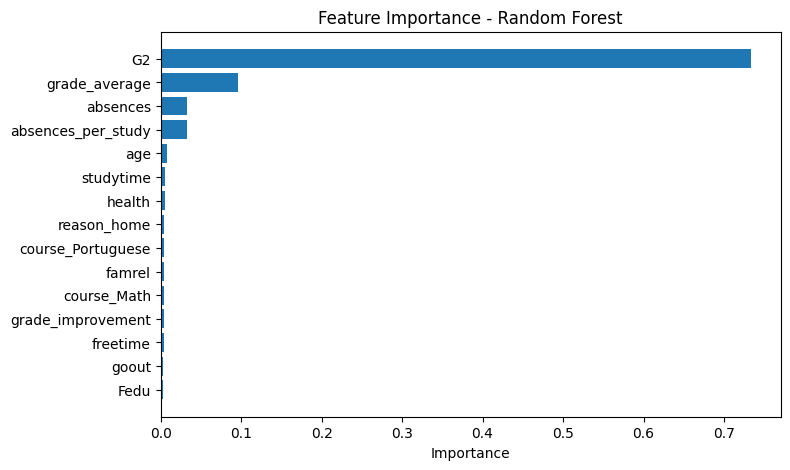

In [27]:
best_model = trained_models[best_regression_model]
feature_names= X_train.columns
if hasattr(best_model,'feature_importances_'):
    model_importance_values = (best_model.feature_importances_)
elif hasattr(best_model,'coef_'):
    model_importance_values = np.abs(best_model.coef_)

model_importance =pd.DataFrame({'Feature': feature_names,'Model_Importance': model_importance_values})
model_importance= (model_importance.sort_values('Model_Importance',ascending=False).reset_index(drop=True))
print(f"Feature importance from {best_regression_model}:")
display(model_importance.head(10).round(3))

fig_model_importance = (model_importance.head(15).sort_values('Model_Importance'))
plt.figure(figsize=(8,5))
plt.barh(fig_model_importance['Feature'],fig_model_importance['Model_Importance'])
plt.xlabel('Importance')
plt.title(f'Feature Importance - {best_regression_model}')
plt.show()

,Feature,Permutation_Importance
0,G2,3.098
1,grade_average,0.255
2,absences_per_study,0.125
3,absences,0.115
4,course_Math,0.034
5,age,0.030
6,studytime,0.028
7,course_Portuguese,0.027
8,health,0.008
9,goout,0.005


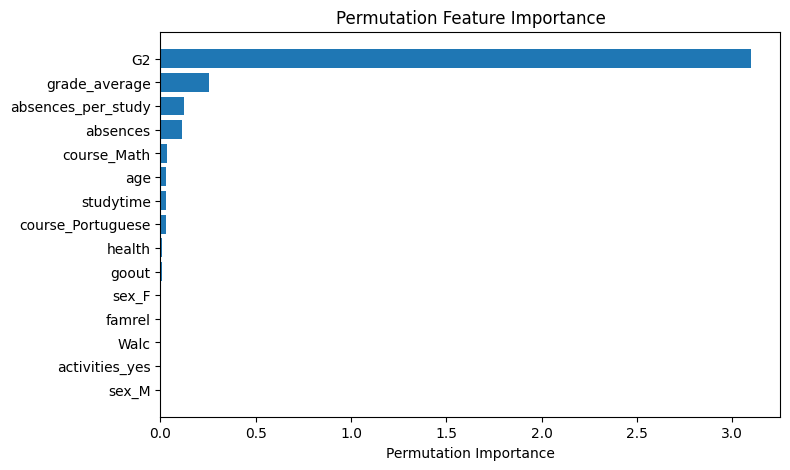

In [28]:
permutation_result = permutation_importance(
    best_model,X_test,y_test,
    n_repeats=20,random_state=RANDOM_STATE,scoring='neg_root_mean_squared_error'
)
permutation_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Permutation_Importance':permutation_result.importances_mean,
})
permutation_df = (permutation_df.sort_values(
        'Permutation_Importance',ascending=False
    ).reset_index(drop=True)
)
display(permutation_df.head(10).round(3))

top_permutation = (permutation_df.head(15).sort_values('Permutation_Importance'))
plt.figure(figsize=(8,5))
plt.barh(top_permutation['Feature'],top_permutation['Permutation_Importance'])
plt.xlabel('Permutation Importance')
plt.title('Permutation Feature Importance')
plt.show()

In [29]:
importance_comparison =pd.merge(
    model_importance[['Feature', 'Model_Importance']],
    permutation_df[['Feature', 'Permutation_Importance']],
    on='Feature',how='inner'
)
importance_comparison['Model_Rank'] = (
    importance_comparison['Model_Importance'].rank(ascending=False)
)
importance_comparison['Permutation_Rank'] = (
    importance_comparison['Permutation_Importance']
    .rank(ascending=False)
)
importance_comparison['Average_Rank'] =(importance_comparison[['Model_Rank','Permutation_Rank']].mean(axis=1))
importance_comparison= (importance_comparison.sort_values('Average_Rank').reset_index(drop=True))
display(importance_comparison.head(10).round(3))

,Feature,Model_Importance,Permutation_Importance,Model_Rank,Permutation_Rank,Average_Rank
0,G2,0.734,3.098,1.000,1.000,1.000
1,grade_average,0.096,0.255,2.000,2.000,2.000
2,absences,0.033,0.115,3.000,4.000,3.500
3,absences_per_study,0.032,0.125,4.000,3.000,3.500
4,age,0.008,0.030,5.000,6.000,5.500
5,studytime,0.005,0.028,6.000,7.000,6.500
6,health,0.005,0.008,7.000,9.000,8.000
7,course_Math,0.005,0.034,11.000,5.000,8.000
8,course_Portuguese,0.005,0.027,9.000,8.000,8.500
9,famrel,0.005,0.005,10.000,12.000,11.000


<div align="right">

## پرسش 8


In [51]:
Q8_NOISE_RATE =0.12
q8_numeric_cols = [c for c in numerical_columns if c in X_encoded.columns]
q8_numeric_index = [X_encoded.columns.get_loc(c)for c in q8_numeric_cols]
original_silhouette = silhouette_score(X_cluster,label_Kmeans)
original_davies_bouldin = davies_bouldin_score(X_cluster,label_Kmeans)
q8_rng =np.random.default_rng(RANDOM_STATE + 800)
BadRows= max(1,int(Q8_NOISE_RATE * len(X_cluster)))
Fixed_BadRows = q8_rng.choice(len(X_cluster),size=BadRows,replace=False)
q8_base_noise = q8_rng.normal(0,1,size=(BadRows,len(q8_numeric_index)))

def add_noise(strength):
    X_noisy = np.array(X_cluster,copy=True)
    X_noisy[np.ix_(Fixed_BadRows,q8_numeric_index)] += (strength*q8_base_noise)
    model = KMeans(n_clusters=2,n_init=50,random_state=RANDOM_STATE)
    labels = model.fit_predict(X_noisy)
    return {
        'strength': strength,'X': X_noisy,
        'bad_rows': Fixed_BadRows.copy(),'labels': labels,
        'Silhouette': silhouette_score(X_noisy,labels),
        'Davies_Bouldin': davies_bouldin_score(X_noisy,labels),
    }
q8_noise_candidates = [
    add_noise(s)
    for s in [1,1.5,2,2.5, 3]]

q8_noise_table = pd.DataFrame([
    {
        'Noise_Strength': r['strength'],
        'Silhouette': r['Silhouette'],
        'Davies_Bouldin': r['Davies_Bouldin'],
    }
    for r in q8_noise_candidates
])
print('Noise sensitivity for K-Means:')
display(q8_noise_table.round(4))

valid_noisy_cases = [r for r in q8_noise_candidates
    if (r['Silhouette'] < original_silhouette and r['Davies_Bouldin'] >original_davies_bouldin)
]

if valid_noisy_cases:
    Noisy_case =max(valid_noisy_cases,key=lambda r: r['strength'])
else:
    Noisy_case = max(
        q8_noise_candidates,
        key=lambda r:
            ((original_silhouette - r['Silhouette']) /max(abs(original_silhouette), 1e-12))
            +
            ((r['Davies_Bouldin']- original_davies_bouldin)/ max(abs(original_davies_bouldin), 1e-12))
    )

X_cluster_noisy = (Noisy_case['X'])
Injected_rows = (Noisy_case['bad_rows'])
NOISE_STRENGTH = (Noisy_case['strength'])
print(f'Injected noisy rows: {len(Injected_rows)}')
print('After adding noise -> Silhouette DOWN, Davies-Bouldin UP')

Noise sensitivity for K-Means:


,Noise_Strength,Silhouette,Davies_Bouldin
0,1.000,0.109,2.826
1,1.500,0.103,2.905
2,2.000,0.098,2.985
3,2.500,0.095,3.054
4,3.000,0.093,3.118


Injected noisy rows: 125
After adding noise -> Silhouette DOWN, Davies-Bouldin UP


In [53]:
def Robust_scores(X_numeric):
    X_numeric = np.asarray(X_numeric, dtype=float)
    Median =np.median(X_numeric, axis=0)
    Mad= np.median(np.abs(X_numeric - Median), axis=0)
    Robust_scale = 1.4826 * Mad
    std_fallback =np.std(X_numeric, axis=0)
    Robust_scale= np.where(Robust_scale < 100000,np.where(std_fallback < 100000, 1.0, std_fallback),Robust_scale)
    z = np.abs((X_numeric - Median) / Robust_scale)
    z= np.minimum(z, 12)
    return np.sqrt(np.mean(z** 2, axis=1))

q8_cluster_scores = Robust_scores(X_cluster_noisy[:, q8_numeric_index])
trim_candidates = []
for trim_rate in [0.06, 0.08, 0.10, 0.12, 0.14]:
    n_trim = max(1,int(trim_rate *len(X_cluster_noisy)))
    detected_rows = np.argsort(q8_cluster_scores)[-n_trim:]
    keep_mask = np.ones(len(X_cluster_noisy),dtype=bool)
    keep_mask[detected_rows] = False
    X_trimmed= X_cluster_noisy[keep_mask]
    model = KMeans(n_clusters=2,n_init=50,random_state=RANDOM_STATE)
    labels_trimmed =model.fit_predict(X_trimmed)
    silhouette2= silhouette_score(X_trimmed,labels_trimmed)
    davies_bouldin2 = davies_bouldin_score(X_trimmed,labels_trimmed)
    detection_precision = (len(set(detected_rows)&set(Injected_rows))/len(detected_rows))
    trim_candidates.append({
        'trim_rate': trim_rate,'detected_rows': detected_rows,'keep_mask': keep_mask,
        'X': X_trimmed,'labels': labels_trimmed,
        'Silhouette': silhouette2,'Davies_Bouldin': davies_bouldin2,
        'Detection_Precision': detection_precision
    })
good_cases = [r for r in trim_candidates
    if (r['Silhouette'] > Noisy_case['Silhouette'] and r['Davies_Bouldin'] < Noisy_case['Davies_Bouldin'])
]
if good_cases:
    Best_trim = max(good_cases,key=lambda r:r['Silhouette']/ r['Davies_Bouldin'])
else:
    Best_trim = max(trim_candidates,key=lambda r: r['Silhouette']/ r['Davies_Bouldin'])

q8_clustering_results = pd.DataFrame([
    {'Data': 'Original',
     'Silhouette': original_silhouette,
     'Davies_Bouldin': original_davies_bouldin,
    },
    {'Data': 'Noisy',
     'Silhouette': Noisy_case['Silhouette'],
     'Davies_Bouldin': Noisy_case['Davies_Bouldin'],
    },
    {'Data': 'After Robust Trimming',
     'Silhouette': Best_trim['Silhouette'],
     'Davies_Bouldin': Best_trim['Davies_Bouldin'],
    }
])
print('Clustering results:')
display(q8_clustering_results.round(4))
if (Best_trim['Silhouette']> Noisy_case['Silhouette'] and Best_trim['Davies_Bouldin'] < Noisy_case['Davies_Bouldin']):
    print('Robust trimming improved both clustering criteria')

Clustering results:


,Data,Silhouette,Davies_Bouldin
0,Original,0.122,2.728
1,Noisy,0.093,3.118
2,After Robust Trimming,0.113,2.767


Robust trimming improved both clustering criteria


In [54]:
numeric_regulation_cols= [c for c in numerical_columns if c !='G3' and c in X_train.columns]
rng_reg = np.random.default_rng(RANDOM_STATE + 800)
X_train_noisy = X_train.copy()
bad_reg = max(1,int(Q8_NOISE_RATE * len(X_train_noisy)))
Bad_train_index = rng_reg.choice(X_train_noisy.index.to_numpy(),size=bad_reg,replace=False)
reg_noise= rng_reg.normal(0,NOISE_STRENGTH,size=(bad_reg, len(numeric_regulation_cols)))
X_train_noisy.loc[Bad_train_index,numeric_regulation_cols] = (
    X_train_noisy.loc[Bad_train_index,numeric_regulation_cols].to_numpy()+reg_noise
)
Reg_noisy_model = clone(regression_models[best_regression_model])
Reg_noisy_model.fit(X_train_noisy,y_train)
Reg_noisy_pred = Reg_noisy_model.predict(X_test)

q8_reg_scores = Robust_scores(X_train_noisy[numeric_regulation_cols].to_numpy())
Detected_train_position = np.argsort(q8_reg_scores)[-max(1,int(Q8_NOISE_RATE * len(X_train_noisy))):]
keep = np.ones(len(X_train_noisy),dtype=bool)
keep[Detected_train_position]= False
X_train_clean = X_train_noisy.iloc[keep]
y_train_clean = y_train.loc[X_train_clean.index]
reg_clean_model = clone(regression_models[best_regression_model])
reg_clean_model.fit(X_train_clean,y_train_clean)
reg_clean_pred = reg_clean_model.predict(X_test)
original_prediction = trained_models[best_regression_model].predict(X_test)
q8_regression_results = pd.DataFrame([
    {'Data': 'Original',
     'MAE': mean_absolute_error(y_test, original_prediction),
     'RMSE': np.sqrt(mean_squared_error(y_test, original_prediction)),
     'R2': r2_score(y_test, original_prediction)
    },
    {'Data': 'Noisy Train',
     'MAE': mean_absolute_error(y_test, Reg_noisy_pred),
     'RMSE': np.sqrt(mean_squared_error(y_test, Reg_noisy_pred)),
     'R2': r2_score(y_test, Reg_noisy_pred)
    },
    {'Data': 'After Robust Trimming',
     'MAE': mean_absolute_error(y_test, reg_clean_pred),
     'RMSE': np.sqrt(mean_squared_error(y_test, reg_clean_pred)),
     'R2': r2_score(y_test, reg_clean_pred)
    }
])
print('Regression results:')
display(q8_regression_results.round(4))

detected_train_index = set(X_train_noisy.index[Detected_train_position])
Reg_detection_precision= (len(detected_train_index & set(Bad_train_index)) /len(detected_train_index))
print('Regression outlier-detection precision:',round(Reg_detection_precision, 3))

Regression results:


,Data,MAE,RMSE,R2
0,Original,0.997,1.654,0.843
1,Noisy Train,0.993,1.620,0.850
2,After Robust Trimming,0.992,1.633,0.847


Regression outlier-detection precision: 0.95


<div align="right">

## پرسش 9


In [59]:
Random_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=RANDOM_STATE,n_jobs=-1),
    param_distributions={
        'n_estimators': [300,500, 700,900],
        'max_depth': [6, 8,10, 12, 16],
        'min_samples_split':[2, 4,6, 10],
        'min_samples_leaf': [1,2, 3, 4,6],
        'max_features': [0.5,0.7, 0.9, 1.0]
    },
    n_iter=20,scoring='neg_root_mean_squared_error',cv=5,random_state=RANDOM_STATE,n_jobs=-1
)
Random_search.fit(X_train,y_train)
Tuned_RF= Random_search.best_estimator_
Tuned_RF_pred = Tuned_RF.predict(X_test)
print('Best Random Forest parameters:')
print(Random_search.best_params_)

Best Random Forest parameters:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 0.5, 'max_depth': 16}


In [60]:
q9_base_models = {
    'Tuned RF': clone(Tuned_RF),'XGBoost': clone(regression_models['XGBoost']),
    'Gradient Boosting': clone(regression_models['Gradient Boosting'])
}
q9_cv = KFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
q9_predictions =[]
Test_predictions= []
Ensemble_models = {}

for model_name, model in q9_base_models.items():
    oof_pred = cross_val_predict(
        model,X_train,y_train,
        cv=q9_cv,n_jobs=1,method='predict'
    )
    fitted_model = clone(model)
    fitted_model.fit(X_train,y_train)
    test_pred = fitted_model.predict(X_test)
    q9_predictions.append(oof_pred)
    Test_predictions.append(test_pred)
    Ensemble_models[model_name] =fitted_model


def Esemble_MSE(weights):
    pred =np.column_stack(q9_predictions) @ weights
    return np.mean((y_train.to_numpy() -pred) **2)

Initial_weights= np.repeat(1/ len(q9_base_models),len(q9_base_models))
q9_optimization = minimize(
    Esemble_MSE,
    x0=Initial_weights,bounds=[(0,1) for _ in q9_base_models],
    constraints={'type': 'eq','fun': lambda w: np.sum(w) -1},method='SLSQP'
)

q9_weights = q9_optimization.x
Ensemble_pred = (np.column_stack(Test_predictions)@ q9_weights)
Weight_table= pd.DataFrame({'Model': list(q9_base_models.keys()),'Weight':q9_weights})
print('Ensemble weights:')
display(Weight_table.round(3))

Ensemble weights:


,Model,Weight
0,Tuned RF,0.490
1,XGBoost,0.000
2,Gradient Boosting,0.510


In [63]:
q9_original_result = regression_results.loc[regression_results['Model'] == best_regression_model].iloc[0]
q9_results = pd.DataFrame([
    {'Method': f'Original {best_regression_model}',
     'MAE': q9_original_result['MAE'],
     'RMSE': q9_original_result['RMSE'],
     'R2': q9_original_result['R2']
    },
    {'Method': 'Tuned Random Forest',
     'MAE': mean_absolute_error(y_test,Tuned_RF_pred),
     'RMSE':np.sqrt(mean_squared_error(y_test,Tuned_RF_pred)),
     'R2': r2_score(y_test,Tuned_RF_pred)
    },
    {'Method': 'Weighted Ensemble',
     'MAE': mean_absolute_error(y_test,Ensemble_pred),
     'RMSE': np.sqrt(mean_squared_error(y_test,Ensemble_pred)),
     'R2':r2_score(y_test,Ensemble_pred)
    }
])
q9_results= (q9_results.sort_values(['RMSE','MAE'],ascending=True).reset_index(drop=True))
display(q9_results.round(3))

q9_best_method =q9_results.iloc[0]['Method']
if q9_best_method =='Tuned Random Forest':
    best_q9_prediction = Tuned_RF_pred
elif q9_best_method== 'Weighted Ensemble':
    best_q9_prediction =Ensemble_pred
else:
    best_q9_prediction= trained_models[best_regression_model].predict(X_test)
print('Best regression result:',q9_best_method)

,Method,MAE,RMSE,R2
0,Tuned Random Forest,0.990,1.632,0.847
1,Weighted Ensemble,1.000,1.652,0.844
2,Original Random Forest,0.997,1.654,0.843


Best regression result: Tuned Random Forest


<div align="right">

## پرسش 10

In [78]:
GRADE_THRESHOLD = 10

y_train_q10 = (y_train < GRADE_THRESHOLD).astype(int)
y_test_q10 =(y_test< GRADE_THRESHOLD).astype(int)
q10_regression_class = (best_q9_prediction < GRADE_THRESHOLD).astype(int)

def q10_metrics(name,y_true,y_pred,risk_score):
    return {
        'Method': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced_Accuracy': balanced_accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred,zero_division=0),
        'Recall': recall_score(y_true, y_pred,zero_division=0),
        'F1': f1_score(y_true, y_pred,zero_division=0),
        'ROC_AUC': roc_auc_score(y_true, risk_score)
    }
q10_rows = []
q10_classifiers = {
    'Logistic Regression': LogisticRegression(
        max_iter=3000,class_weight='balanced',random_state=RANDOM_STATE
    ),
    'Random Forest Classifier': RandomForestClassifier(
        n_estimators=500,class_weight='balanced_subsample',
        random_state=RANDOM_STATE,n_jobs=-1
    ),
    'Histogram Gradient Boosting': HistGradientBoostingClassifier(
        learning_rate=0.05,max_iter=300,
        l2_regularization=1.0,random_state=RANDOM_STATE
    )
}
q10_fitted_models = {}
q10_balanced_weights = compute_sample_weight(class_weight='balanced',y=y_train_q10)
for model_name, model in q10_classifiers.items():
    if model_name== 'Histogram Gradient Boosting':
        model.fit(X_train,y_train_q10,sample_weight=q10_balanced_weights)
    else:
        model.fit(X_train,y_train_q10)

    pred =model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    q10_rows.append(q10_metrics(model_name,y_test_q10,pred,proba))
    q10_fitted_models[model_name] =model

q10_results= pd.DataFrame(q10_rows)
q10_results = (
    q10_results
    .sort_values(['F1','Balanced_Accuracy'],ascending=False).reset_index(drop=True))
display(q10_results.round(3))

,Method,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC
0,Histogram Gradient Boosting,0.900,0.875,0.807,0.821,0.814,0.967
1,Random Forest Classifier,0.900,0.858,0.843,0.768,0.804,0.973
2,Logistic Regression,0.871,0.872,0.710,0.875,0.784,0.959


In [86]:
q10_confusion_rows = []
q10_predictions = {}
for model_name, model in q10_fitted_models.items():
    q10_predictions[model_name] = model.predict(X_test)

for method,pred in q10_predictions.items():
    TN,FP,FN,TP = confusion_matrix(y_test_q10,pred,labels=[0, 1]).ravel()
    q10_confusion_rows.append({
        'Method': method,
        'TN': TN,'FP':FP,'FN': FN,'TP':TP
    })
q10_confusion = pd.DataFrame(q10_confusion_rows)
display(q10_confusion)

q10_best_method = q10_results.iloc[0]
print('Best method by F1:',q10_best_method['Method'])
print(f"F1 = {q10_best_method['F1']:.3f}")
print(f"Balanced Accuracy = {q10_best_method['Balanced_Accuracy']:.3f}")

,Method,TN,FP,FN,TP
0,Logistic Regression,133,20,7,49
1,Random Forest Classifier,145,8,13,43
2,Histogram Gradient Boosting,142,11,10,46


Best method by F1: Histogram Gradient Boosting
F1 = 0.814
Balanced Accuracy = 0.875
